In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

plt.style.use("ggplot")

In [2]:
train_csv = "../dataset/train.csv"

df = pd.read_csv(train_csv)

df.head()

,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


In [3]:
print("Shape:", df.shape)

df.info()

Shape: (3662, 2)
<class 'pandas.DataFrame'>
RangeIndex: 3662 entries, 0 to 3661
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   id_code    3662 non-null   str  
 1   diagnosis  3662 non-null   int64
dtypes: int64(1), str(1)
memory usage: 57.3 KB


In [4]:
df.isnull().sum()

id_code      0
diagnosis    0
dtype: int64

In [ ]:
df.describe()

In [ ]:
class_counts = df["diagnosis"].value_counts().sort_index()

print(class_counts)

In [ ]:
plt.figure(figsize=(8,5))

class_counts.plot(kind="bar")

plt.title("Distribution of Diabetic Retinopathy Classes")

plt.xlabel("Diagnosis")

plt.ylabel("Number of Images")

plt.show()

In [8]:
label_map = {
    0:"No DR",
    1:"Mild",
    2:"Moderate",
    3:"Severe",
    4:"Proliferative DR"
}

label_map

{0: 'No DR', 1: 'Mild', 2: 'Moderate', 3: 'Severe', 4: 'Proliferative DR'}

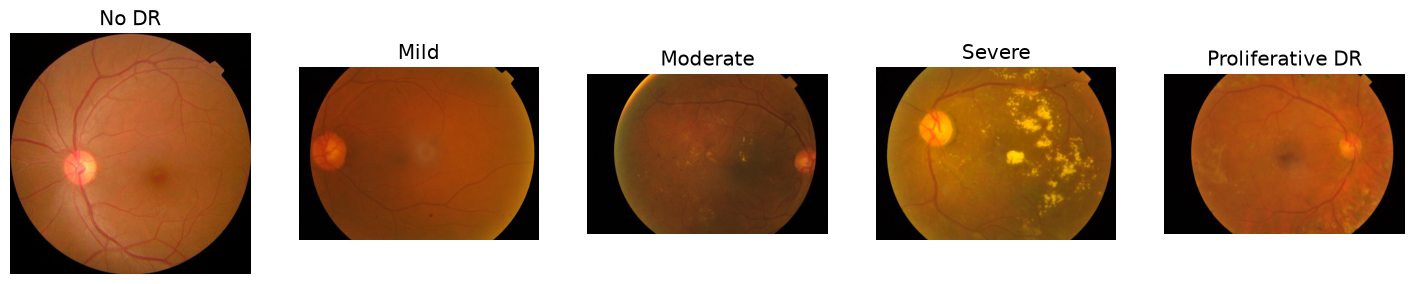

In [9]:
image_folder = "../dataset/train_images"

plt.figure(figsize=(18,10))

for diagnosis in range(5):

    image_name = df[df["diagnosis"] == diagnosis].iloc[0]["id_code"]

    image_path = os.path.join(image_folder, image_name + ".png")

    image = Image.open(image_path)

    plt.subplot(1,5,diagnosis+1)

    plt.imshow(image)

    plt.title(label_map[diagnosis])

    plt.axis("off")

plt.show()

In [ ]:
sizes = []

for image_name in df["id_code"][:100]:
    
    image_path = os.path.join(image_folder, image_name + ".png")

    image = Image.open(image_path)

    sizes.append(image.size)

sizes[:10]

In [5]:
class_counts = df["diagnosis"].value_counts().sort_index()

print(class_counts)

diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


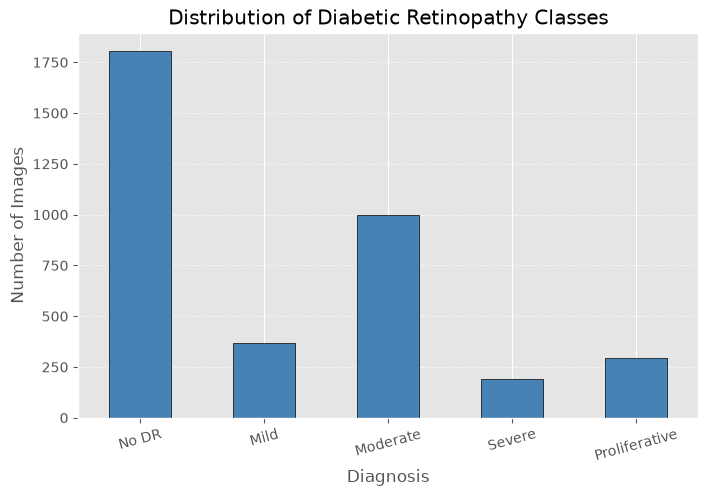

In [6]:
plt.figure(figsize=(8,5))

class_counts.plot(
    kind="bar",
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribution of Diabetic Retinopathy Classes")

plt.xlabel("Diagnosis")

plt.ylabel("Number of Images")

plt.xticks(
    ticks=[0,1,2,3,4],
    labels=[
        "No DR",
        "Mild",
        "Moderate",
        "Severe",
        "Proliferative"
    ],
    rotation=15
)

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()